<a href="https://colab.research.google.com/github/nataga-10/chatbot_react/blob/main/Jer%C3%A1rquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 1 · Clustering con K-means — Dataset *Wine*
**CADI Introducción a Machine Learning — Universidad de Cundinamarca**
**Autora:** Angie Tatiana Reyes Sanchez

**Objetivo:** agrupar 178 vinos a partir de 13 mediciones químicas **sin usar la etiqueta** de cultivar, elegir el número de grupos con el método del codo y el coeficiente de silueta, y comprobar después si los grupos encontrados coinciden con los tres cultivares reales.

**Algoritmo:** K-means (Lloyd, 1982; MacQueen, 1967) con inicialización *k-means++* (Arthur & Vassilvitskii, 2007), implementado con Scikit-learn (Pedregosa et al., 2011).

In [1]:
# Librerías base (todas vienen preinstaladas en Google Colab)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)   # carpeta donde se guardan las figuras del informe
np.random.seed(42)

# Paleta de colores del proyecto (morados, rosas y lavandas)
PALETA = ["#6A3D9A", "#E7298A", "#1B9E77", "#F28E2B", "#5B8DEF", "#B07AA1"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=PALETA),
})

## 1. Carga y exploración de los datos
El dataset *Wine* (Aeberhard & Forina, 1991) viene incluido en Scikit-learn, así que no hay que descargar nada.

In [2]:
from sklearn.datasets import load_wine

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_real = wine.target            # solo se usa al final para EVALUAR, nunca para entrenar

print("Dimensiones:", X.shape)
print("Valores nulos:", X.isna().sum().sum())
print("Muestras por cultivar real:", np.bincount(y_real))
display(X.describe().T[["mean", "std", "min", "max"]].round(2))

Dimensiones: (178, 13)
Valores nulos: 0
Muestras por cultivar real: [59 71 48]


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Las variables tienen escalas muy distintas (por ejemplo, *proline* llega a 1680 y *hue* no pasa de 1.71). Como K-means usa distancia euclidiana, sin escalar la variable más grande dominaría el agrupamiento. Por eso se estandariza cada variable: $z = (x - \mu)/\sigma$.

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

print("Media después de escalar (primeras 4):", X_std.mean(axis=0)[:4].round(3))
print("Desv. estándar después de escalar (primeras 4):", X_std.std(axis=0)[:4].round(3))

Media después de escalar (primeras 4): [ 0.  0. -0. -0.]
Desv. estándar después de escalar (primeras 4): [1. 1. 1. 1.]


## 2. Selección del número de clusters *k*
- **Método del codo:** se grafica la inercia (suma de distancias cuadradas de cada punto a su centroide, WCSS) para k = 1…10 y se busca el punto donde deja de bajar con fuerza.
- **Coeficiente de silueta** (Rousseeuw, 1987): para cada punto, $s = (b - a)/\max(a, b)$, donde *a* es la distancia media a su propio cluster y *b* la distancia media al cluster vecino más cercano. Va de −1 a 1; más alto es mejor.

,k,inercia,silueta
0,1,2314.0,NaN
1,2,1658.8,0.259
2,3,1277.9,0.285
3,4,1175.4,0.260
4,5,1109.5,0.202
5,6,1046.0,0.237
6,7,981.6,0.204
7,8,935.2,0.157
8,9,889.9,0.150
9,10,845.9,0.144


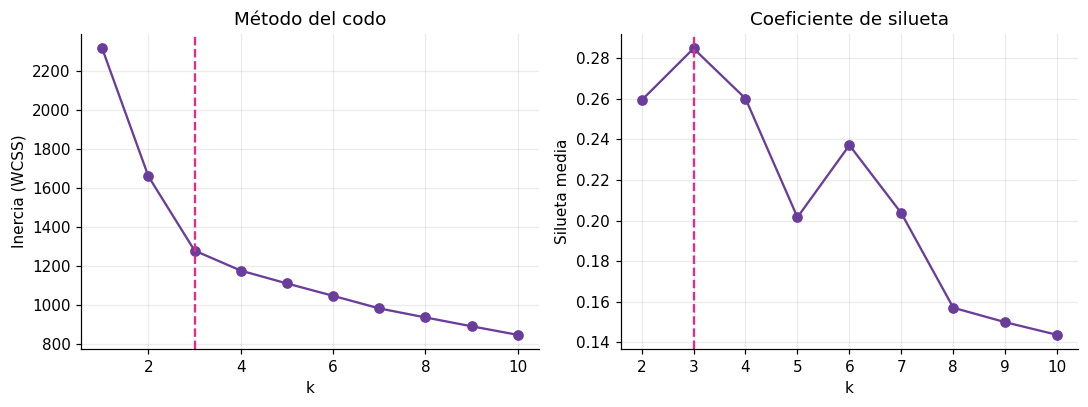

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(1, 11)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X_std)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_std, km.labels_) if k > 1 else np.nan)

tabla_k = pd.DataFrame({"k": list(ks), "inercia": np.round(inercias, 1), "silueta": np.round(siluetas, 3)})
display(tabla_k)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(ks, inercias, "o-", color=PALETA[0])
ax[0].axvline(3, ls="--", color=PALETA[1]); ax[0].set(title="Método del codo", xlabel="k", ylabel="Inercia (WCSS)")
ax[1].plot(list(ks)[1:], siluetas[1:], "o-", color=PALETA[0])
ax[1].axvline(3, ls="--", color=PALETA[1]); ax[1].set(title="Coeficiente de silueta", xlabel="k", ylabel="Silueta media")
plt.tight_layout(); plt.savefig("figuras/fig01_codo_silueta.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Modelo final con k = 3

In [5]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
etiquetas_km = kmeans.fit_predict(X_std)

print("Iteraciones hasta converger:", kmeans.n_iter_)
print("Inercia final:", round(kmeans.inertia_, 2))
print("Silueta media:", round(silhouette_score(X_std, etiquetas_km), 4))
print("Tamaño de cada cluster:", np.bincount(etiquetas_km))

Iteraciones hasta converger: 7
Inercia final: 1277.93
Silueta media: 0.2849
Tamaño de cada cluster: [65 51 62]


### 3.1 Ejemplo numérico: asignación de un vino a su centroide
K-means asigna cada punto al centroide más cercano. Se verifica a mano con el primer vino del dataset usando $d = \sqrt{\sum (x_i - c_i)^2}$.

In [6]:
x0 = X_std[0]
distancias = np.sqrt(((kmeans.cluster_centers_ - x0) ** 2).sum(axis=1))
for c, d in enumerate(distancias):
    print(f"Distancia euclidiana del vino 0 al centroide {c}: {d:.4f}")
print("Centroide más cercano (cálculo manual):", distancias.argmin())
print("Cluster asignado por Scikit-learn:   ", etiquetas_km[0])

Distancia euclidiana del vino 0 al centroide 0: 4.9629
Distancia euclidiana del vino 0 al centroide 1: 6.2931
Distancia euclidiana del vino 0 al centroide 2: 2.0634
Centroide más cercano (cálculo manual): 2
Cluster asignado por Scikit-learn:    2


### 3.2 Perfil de cada cluster (en unidades originales)
Se regresan los centroides a la escala original con la transformación inversa del escalador ($x = z\sigma + \mu$) para interpretarlos.

,alcohol,malic_acid,flavanoids,color_intensity,hue,proline
Cluster 0,12.25,1.90,2.05,2.97,1.06,510.17
Cluster 1,13.13,3.31,0.82,7.23,0.69,619.06
Cluster 2,13.68,2.00,3.00,5.45,1.07,1100.23


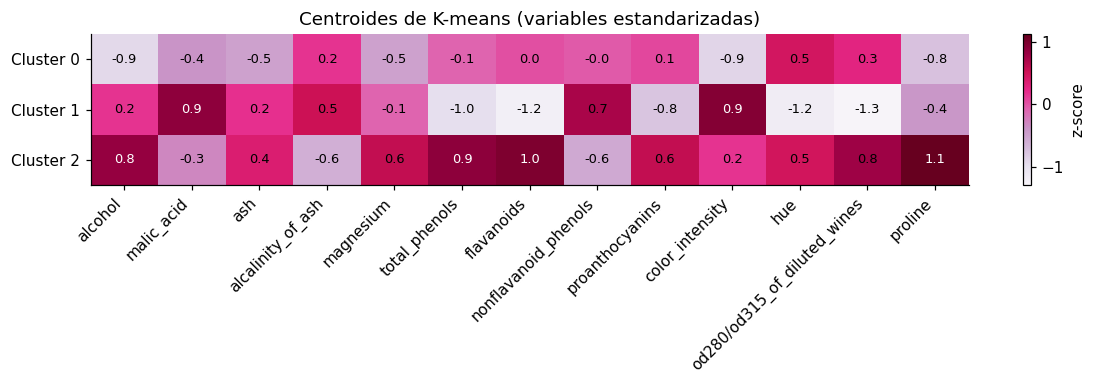

In [7]:
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=wine.feature_names)
centroides.index = [f"Cluster {i}" for i in range(3)]
display(centroides[["alcohol", "malic_acid", "flavanoids", "color_intensity", "hue", "proline"]].round(2))

# Mapa de calor de los centroides estandarizados (z-scores)
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(kmeans.cluster_centers_, cmap="PuRd", aspect="auto")
ax.set_xticks(range(13)); ax.set_xticklabels(wine.feature_names, rotation=45, ha="right")
ax.set_yticks(range(3)); ax.set_yticklabels(centroides.index); ax.grid(False)
for i in range(3):
    for j in range(13):
        v = kmeans.cluster_centers_[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8.5, color="white" if v > 0.8 else "black")
plt.colorbar(im, ax=ax, label="z-score"); ax.set_title("Centroides de K-means (variables estandarizadas)")
plt.tight_layout(); plt.savefig("figuras/fig02_centroides_heatmap.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Visualización de los clusters
Los datos tienen 13 dimensiones; para dibujarlos se proyectan sobre los dos primeros componentes principales (PCA, ver Notebook 3). La proyección solo se usa para graficar: el clustering se hizo en las 13 dimensiones.

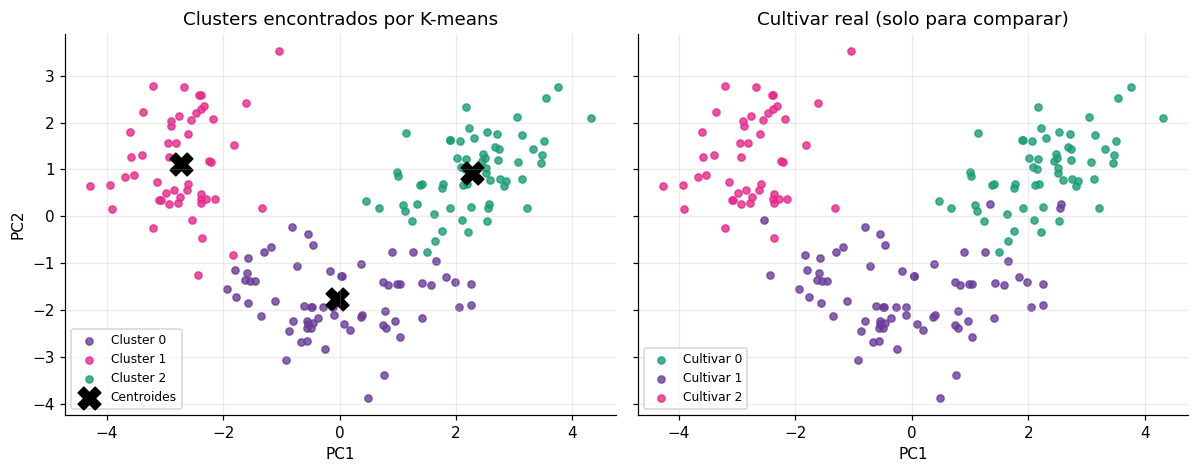

In [8]:
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2).fit(X_std)
Z = pca2.transform(X_std)
C = pca2.transform(kmeans.cluster_centers_)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
# color de cada cultivar = color del cluster donde cae la mayoría de sus vinos
color_cultivar = pd.crosstab(y_real, etiquetas_km).idxmax(axis=1).to_dict()
for c in range(3):
    ax[0].scatter(*Z[etiquetas_km == c].T, s=22, alpha=.8, color=PALETA[c], label=f"Cluster {c}")
    ax[1].scatter(*Z[y_real == c].T, s=22, alpha=.8, color=PALETA[color_cultivar[c]], label=f"Cultivar {c}")
ax[0].scatter(*C.T, marker="X", s=220, c="black", label="Centroides")
ax[0].set(title="Clusters encontrados por K-means", xlabel="PC1", ylabel="PC2")
ax[1].set(title="Cultivar real (solo para comparar)", xlabel="PC1")
ax[0].legend(fontsize=8); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figuras/fig03_kmeans_pca.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Validación
### 5.1 Gráfico de silueta por muestra

Cluster 0: silueta media = 0.177, puntos con s<0 = 7
Cluster 1: silueta media = 0.351, puntos con s<0 = 0
Cluster 2: silueta media = 0.343, puntos con s<0 = 0


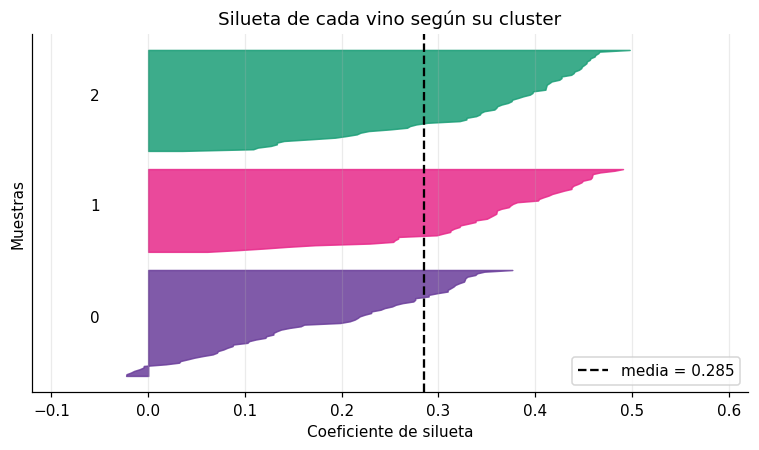

In [9]:
from sklearn.metrics import silhouette_samples

s_i = silhouette_samples(X_std, etiquetas_km)
fig, ax = plt.subplots(figsize=(7, 4.2))
y0 = 10
for c in range(3):
    vals = np.sort(s_i[etiquetas_km == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, color=PALETA[c], alpha=.85)
    ax.text(-0.06, y0 + len(vals) / 2, str(c))
    print(f"Cluster {c}: silueta media = {vals.mean():.3f}, puntos con s<0 = {(vals < 0).sum()}")
    y0 += len(vals) + 10
ax.set_xlim(-0.12, 0.62)
ax.axvline(s_i.mean(), ls="--", color="black", label=f"media = {s_i.mean():.3f}")
ax.set(title="Silueta de cada vino según su cluster", xlabel="Coeficiente de silueta", ylabel="Muestras"); ax.set_yticks([])
ax.legend(); plt.tight_layout(); plt.savefig("figuras/fig04_silueta_muestras.png", dpi=200, bbox_inches="tight"); plt.show()

### 5.2 Comparación con las etiquetas reales (validación externa)
Ahora sí se usan los cultivares reales, únicamente para medir qué tan bien K-means "descubrió" la estructura. Se usa una tabla de contingencia y el **Índice de Rand Ajustado** (ARI; Hubert & Arabie, 1985), que vale 1 si las particiones son idénticas y ≈0 si coinciden por azar.

In [10]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

tabla = pd.crosstab(pd.Series(y_real, name="Cultivar real"), pd.Series(etiquetas_km, name="Cluster K-means"))
display(tabla)
aciertos = tabla.max(axis=1).sum()
print(f"Vinos en el cluster mayoritario de su cultivar: {aciertos}/178 = {aciertos/178:.2%}")
print("ARI:", round(adjusted_rand_score(y_real, etiquetas_km), 4))
print("NMI:", round(normalized_mutual_info_score(y_real, etiquetas_km), 4))

Cluster K-means,0,1,2
Cultivar real,,,
0,0,0,59
1,65,3,3
2,0,48,0


Vinos en el cluster mayoritario de su cultivar: 172/178 = 96.63%
ARI: 0.8975
NMI: 0.8759


### 5.3 ¿Qué pasa si NO se estandariza?

In [11]:
km_sin = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
print("ARI sin estandarizar:", round(adjusted_rand_score(y_real, km_sin.labels_), 4))
print("ARI estandarizando:  ", round(adjusted_rand_score(y_real, etiquetas_km), 4))

ARI sin estandarizar: 0.3711
ARI estandarizando:   0.8975


## 6. Análisis de resultados
1. **Número de clusters.** El codo de la inercia aparece en k = 3 (de 1658.8 baja a 1277.9 y luego solo a 1175.4) y la silueta media alcanza su máximo, 0.285, también en k = 3. Ambos criterios coinciden.
2. **Calidad interna.** Una silueta de 0.285 indica clusters reales pero con cierto solapamiento. El cluster 0 es el menos compacto (silueta 0.177 y 7 vinos con valor negativo); los clusters 1 y 2 son más nítidos (≈0.35).
3. **Interpretación química.** El cluster 2 agrupa vinos con más alcohol (13.68 %), flavonoides (3.00) y prolina (≈1100); el cluster 1, vinos con intensidad de color alta (7.23), tono bajo (0.69) y pocos flavonoides (0.82); el cluster 0, vinos de menor alcohol (12.25 %) y color suave (2.97).
4. **Validación externa.** Sin haber visto las etiquetas, K-means ubicó 172 de 178 vinos (96.6 %) en el grupo de su cultivar, con ARI = 0.898 y NMI = 0.876. Los 6 errores son vinos del cultivar 1.
5. **Importancia del preprocesamiento.** Sin estandarizar, el ARI cae a 0.371, porque la prolina (escala de cientos) domina la distancia euclidiana.